# QUASTELL demo: background, thermodynamics and QNMs

Every functionality of the `QUASTELL` package, one per cell, on the Bea-Mateos model with `phiM = 1`, `phiQ = 10`, `chi = 1.2`. Its spinodal branch (`ds/dT < 0`) is `phiH` between 1.033 and 1.271.

All grids stay at `N <= 60`: from `N ~ 70` the background Newton residual floors above its tolerance and every new background takes minutes.

### Setup
Activate the project this notebook belongs to (the repository root, one level up). The first time, `Pkg.instantiate()` installs the dependencies.

`Bea_Mateos(phiM, phiQ; chi, nu)` builds V, V', V'' and locates `phiMax`.

In [1]:
using Pkg
Pkg.activate("..")
Pkg.instantiate()

using QUASTELL
using LinearAlgebra, Printf, Plots, ProgressMeter

m = Bea_Mateos(1.0, 10; chi = 1.2)

    \o/                                                                               \o/
     |                                                                                 |
   o/ \o        ___    _   _      _      ____    _____   _____   _       _           o/ \o
  /|\ /|\      / _ \  | | | |    / \    / ___|  |_   _| | ____| | |     | |         /|\ /|\
 o/ \o/ \o    | | | | | | | |   / _ \   \___ \    | |   |  _|   | |     | |        o/ \o/ \o
/|\ /|\ /|\   | |_| | | |_| |  / ___ \   ___) |   | |   | |___  | |___  | |___    /|\ /|\ /|\
/ \ / \ / \    \__\_\  \___/  /_/   \_\ |____/    |_|   |_____| |_____| |_____|   / \ / \ / \
                          QUAsinormal Spectra of ThErmaL hoLography



  Activating project at `c:\Users\pedro\Desktop\ESTUDIOS\PhD in Theoretical Physics\3 year\Instabilities_project\QNMs codes\QUASTELL`


Bea_Mateos(phiM = 1.0, phiQ = 10.0, chi = 1.2, nu = 1.0)
  phiMax = 1.539456   V(phiMax) = -7.14223
  cached backgrounds: 0   thermodynamics: not computed   Tc: -
  QNM runs: 0

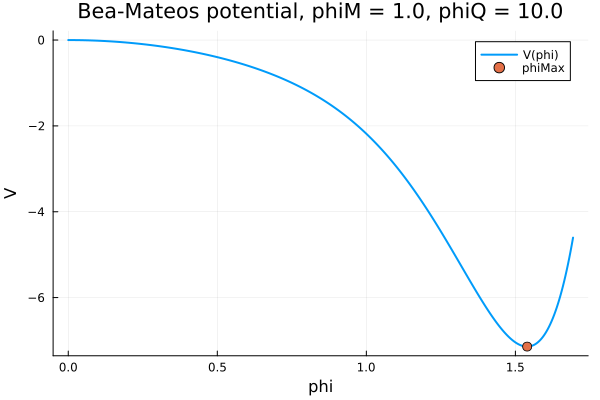

In [2]:
plot_potential(m)

### 1. Background at one phiH
Damped Newton with continuation from pure AdS. Cached by `(N, phiH)`.

In [3]:
bg = background(m, 0.3; N = 40)
@printf("T = %.8g   S = %.8g   Lambda = %.8g   res = %.2e   converged = %s\n",
        bg.T, bg.S, bg.Lambda, bg.res, bg.converged)
@printf("T/Lambda = %.8g   s/Lambda^3 = %.8g\n", bg.T/bg.Lambda, bg.S/bg.Lambda^3)

T = 0.31942632   S = 2.964797   Lambda = 0.35152238   res = 7.29e-11   converged = true
T/Lambda = 0.90869412   s/Lambda^3 = 68.255245


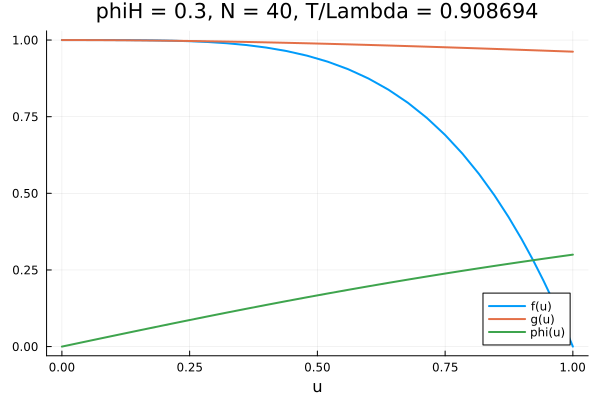

In [4]:
plot_solution(m, bg)

### 2. Full thermodynamics
Sweep phiH up to `phiMax`; failed solves stay `NaN`. `F = -p` with `p` from `dp = s dT` anchored at the coldest point, so it is a free energy up to a constant; `eps = sT - p`.

In [5]:
th = thermodynamics!(m; N = 50, nphi = 2000, progress = true);
@printf("converged %d/%d   Tc = %s\n", count(th.converged), length(th.converged),
        string(m.Tc))
i0 = findfirst(th.converged)
@printf("conformal check at the hot end: eps/(3p) = %.6f   (eps+p)/(sT) = %.8f\n",
        th.e[i0]/(3*th.p[i0]), (th.e[i0]+th.p[i0])/(th.s[i0]*th.t[i0]))

thermodynamics: 100%|███████████████████████████████████| Time: 0:01:12


converged 2000/2000   Tc = 0.37356749557573704
conformal check at the hot end: eps/(3p) = 1.000749   (eps+p)/(sT) = 1.00000000


┌ Info: critical temperature
│   Tc = 0.37356749557573704
└ @ QUASTELL c:\Users\pedro\Desktop\ESTUDIOS\PhD in Theoretical Physics\3 year\Instabilities_project\QNMs codes\QUASTELL\src\thermodynamics.jl:65


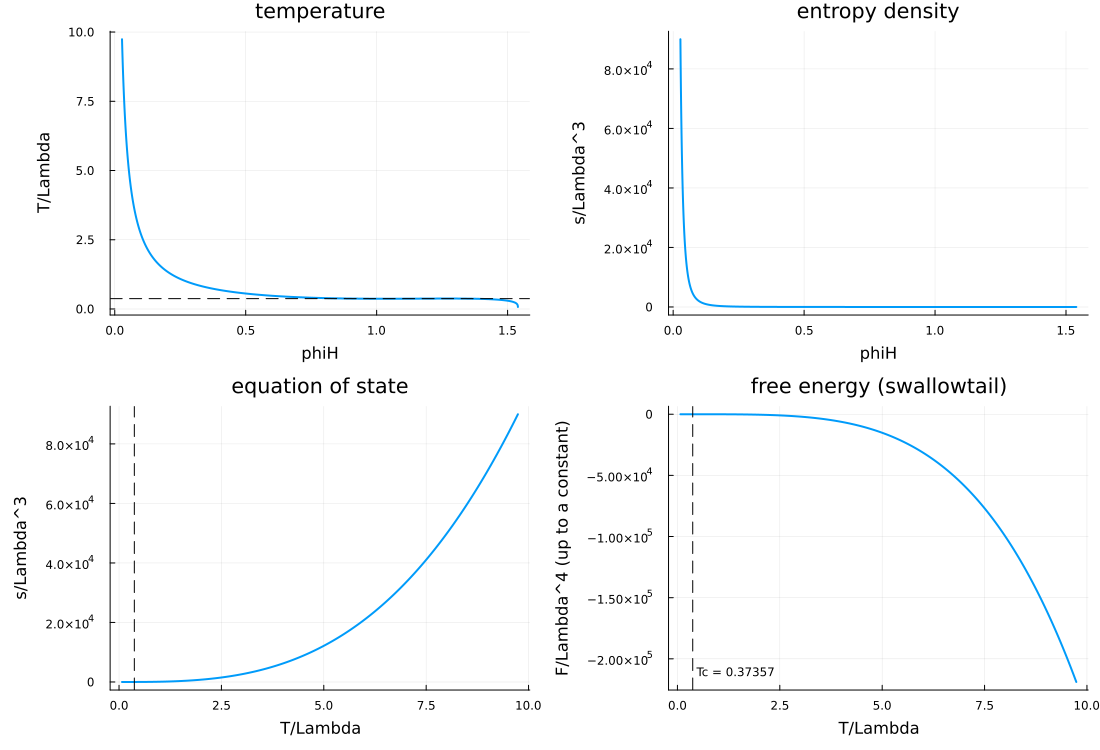

In [6]:
plot_thermodynamics(m)

`zoom = w` restricts the T axis to `Tc*(1 +- w)`; the three branches of `F` cross at `Tc`.

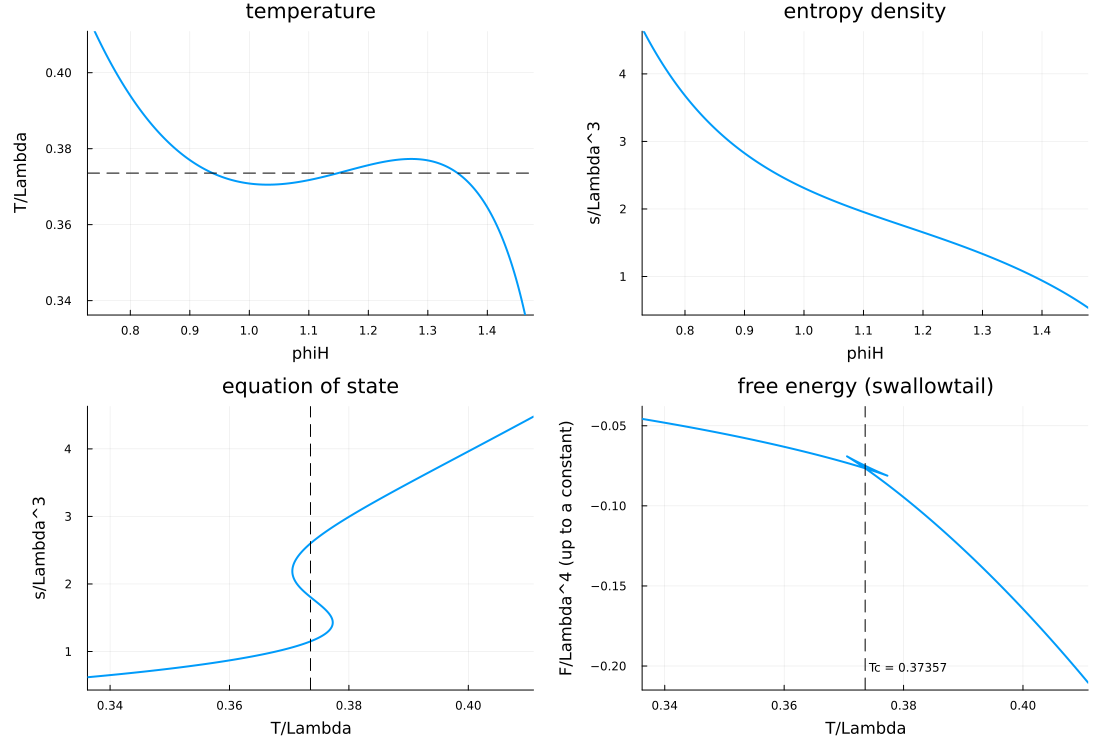

In [7]:
plot_thermodynamics(m; zoom = 0.1)

### 3. The fluctuation matrices
`M(w) = Mt[1] + w Mt[2] + w^2 Mt[3] + w^3 Mt[4]`; `M0, M1` are the companion form.

Two steps happen first. `rescale_fields!` substitutes `Zphi = u^2 Ztilde`: the normalizable branch is `u^3` and the discarded one `u^1`, so without this both are ordinary polynomials, nothing excludes the sourced solution, and the entire Zphi tower is missing. Then `boundary_rows!` fills rows 1, N+1 and N, which the bulk equations leave empty.

In [8]:
M0, M1, Mt, b = mtildes(m, 0.3; q = 0.3, N = 40);
@printf("%d blocks of %s   companion %s\n", length(Mt), string(size(Mt[1])),
        string(size(M0)))
w = 1.234 + 0.567im
M = Mt[1] + w*Mt[2] + w^2*Mt[3] + w^3*Mt[4]
@printf("rank M(w) = %d of %d   (must be full, else det = 0 identically)\n",
        rank(M), size(M, 1))

4 blocks of (80, 80)   companion (240, 240)
rank M(w) = 79 of 80   (must be full, else det = 0 identically)


┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 62.4
│   queued_messages = 0
└ @ VSCodeServer.JSONRPC c:\Users\pedro\.vscode\extensions\julialang.language-julia-1.250.2\scripts\packages\JSONRPC\src\core.jl:414


Without the boundary rows, two rows are identically zero and the pencil is singular:

In [9]:
_, _, Mt0, _ = mtildes(m, 0.3; q = 0.3, N = 40, bc = false);
Mraw = Mt0[1] + w*Mt0[2] + w^2*Mt0[3] + w^3*Mt0[4]
@printf("rank without bc = %d of %d\n", rank(Mraw), size(Mraw, 1))
@printf("|row 40| = %.2e   |row 41| = %.2e   typical row = %.2e\n",
        norm(Mraw[40, :]), norm(Mraw[41, :]), norm(Mraw[20, :]))

rank without bc = 78 of 80
|row 40| = 3.79e+05   |row 41| = 0.00e+00   typical row = 5.78e+03


And without the rescaling the Zphi tower disappears while everything else is untouched -- compare the two lists:

In [10]:
for rs in ((0, 0), (2, 0))
    rr = qnms(m, 1e-3; q = 0.05, Ns = (40, 50, 60), rtol = 1e-4, cutoff = 40.0,
              verbose = false, rescale = rs)
    p = sort(filter(z -> real(z) > 1e-6, rr.lambda), by = z -> -imag(z))
    @printf("rescale = %-7s : %s\n", string(rs),
            join([@sprintf("%.4f%+.4fi", real(z), imag(z)) for z in p], "  "))
end

rescale = (0, 0)  : 0.0289-0.0008i  1.1010-0.8795i  1.5601-1.3732i  2.1069-1.8872i  2.5850-2.3817i  3.1085-2.8884i  3.5942-3.3847i
rescale = (2, 0)  : 0.0289-0.0008i  1.1010-0.8795i  1.5601-1.3732i  2.1069-1.8872i  2.5850-2.3817i  3.1085-2.8884i  3.5942-3.3847i


The export also carries a spurious overall factor of `f` in equation 1, which kills its row at the horizon; `boundary_rows!` then has to impose the derivation's ingoing condition, whose derivative part factors as `(f'(1)sqrt(g(1)) + 4 i pi T lambda)(...)` with `f'(1)sqrt(g(1)) = -4 pi T` identically -- so it vanishes at `lambda = -i` and parks a spurious mode there, for every background and momentum.

`divide_f = true` (the default) divides the factor out instead, at the level of the coefficient functions of `a Z'' + b Z' + c Z`, taking the horizon value from the limit `ahat(1) = a'(1)/f'(1)`. Neither cheaper route works: the division cannot be done symbolically, because with `f, g, phi, V` as free symbols the `omega^0` `Z2` coefficient does not vanish at `u = 1` (its vanishing is on-shell), so `Cancel` would need the background equations of motion the master equations were already derived with; and it cannot be done by a row operation either, because the `u = 1` row is identically zero, so any combination of rows already lies in the row space and the rank cannot change.

Read the rank *after* row balancing. Before balancing it reads one short, but the near-null direction is equation 2 at the second gridpoint, whose row norm is ~1e-9 of the largest because of *its* own overall factor of `u` -- nothing to do with the `f` division. `_spectrum` balances, so the pencil handed to `eigvals` is nonsingular.

**`rtol` matters here.** The divided pencil is worse conditioned (cond ~1e12 at N = 90 against ~2e5), so eigenvalues carry an error of order 1e-4 and a nearly-real mode can have its imaginary part smeared onto the wrong side of zero. At `phiH = 0.3, q = 0.3` -- `T/Lambda = 0.905`, far above `Tc`, so certainly stable -- a spurious pair at `+-0.339 + 9e-5i` survives a three-grid filter at `rtol = 1e-3` or looser, and is rejected at the default `rtol = 1e-4`. So read stability only at `rtol <= 1e-4`. The dispersion and growth-rate cells below use `rtol = 1e-4` too: at `1e-2`, singular-band artifacts survive at small `q` and get picked up as branches.

In [11]:
function ranks(m, phiH, q, N, df)
    _, _, Mt, b = mtildes(m, phiH; q = q, N = N, divide_f = df)
    sc = 2pi*b.T
    A  = [ComplexF64.(Mt[n]) .* sc^(n-1) for n in eachindex(Mt)]
    for i in axes(A[1], 1)                      # row balancing, as in _spectrum
        s = maximum(maximum(abs, view(X, i, :)) for X in A)
        s > 0 && for X in A; @views X[i, :] ./= s; end
    end
    wg = 1.234+0.567im
    Mr = Mt[1] + wg*Mt[2] + wg^2*Mt[3] + wg^3*Mt[4]
    Mb = A[1]  + wg*A[2]  + wg^2*A[3]  + wg^3*A[4]
    return rank(Mr), rank(Mb), size(Mb, 1)
end

for df in (false, true)
    rr = qnms(m, 1e-3; q = 0.05, Ns = (40, 50, 60), rtol = 1e-4, cutoff = 40.0,
              verbose = false, divide_f = df)
    pim = filter(z -> abs(real(z)) < 1e-6 && abs(z) < 6, rr.lambda)
    r0, r1, nn = ranks(m, 1e-3, 0.05, 60, df)
    @printf("divide_f = %-5s : rank %d/%d raw, %d/%d balanced , lambda = -i %s\n",
            df, r0, nn, r1, nn, isempty(pim) ? "absent" : "PRESENT")
    for z in sort(filter(z -> real(z) > 1e-6, rr.lambda), by = z -> -imag(z))
        @printf("      %+.9f %+.9f i\n", real(z), imag(z))
    end
end

# On the spinodal branch, and on a stable background for comparison.
println()
for df in (false, true)
    rs = qnms(m, 1.16; q = 0.05, Ns = (40, 50, 60), rtol = 1e-4, cutoff = 40.0,
              verbose = false, divide_f = df, bcexpand = true)
    up = filter(z -> imag(z) > 1e-8, rs.lambda)
    @printf("phiH = 1.16 (spinodal) , q = 0.05 , divide_f = %-5s : %d unstable %s\n",
            df, length(up), join([@sprintf("%+.6fi", imag(z)) for z in up], " "))
end
for df in (false, true)
    rs = qnms(m, 0.3; q = 0.3, Ns = (40, 50, 60), rtol = 1e-4, cutoff = 40.0,
              verbose = false, divide_f = df)
    @printf("phiH = 0.3  (T/Lambda = 0.905, stable) , q = 0.3 , divide_f = %-5s : %d with Im > 0\n",
            df, count(z -> imag(z) > 1e-8, rs.lambda))
end

divide_f = false : rank 120/120 raw, 120/120 balanced , lambda = -i PRESENT
      +0.028886921 -0.000833145 i
      +1.560121984 -1.373217473 i
      +2.585041532 -2.381706215 i
      +3.594197594 -3.384737506 i
divide_f = true  : rank 119/120 raw, 120/120 balanced , lambda = -i absent
      +0.028886921 -0.000833145 i
      +1.100993211 -0.879452181 i
      +1.560121984 -1.373217473 i
      +2.106941926 -1.887210422 i
      +2.585041512 -2.381706207 i
      +3.108525176 -2.888446924 i
      +3.594203091 -3.384728760 i

phiH = 1.16 (spinodal) , q = 0.05 , divide_f = false : 1 unstable +0.011068i
phiH = 1.16 (spinodal) , q = 0.05 , divide_f = true  : 1 unstable +0.011068i
phiH = 0.3  (T/Lambda = 0.905, stable) , q = 0.3 , divide_f = false : 0 with Im > 0
phiH = 0.3  (T/Lambda = 0.905, stable) , q = 0.3 , divide_f = true  : 0 with Im > 0


### 4. The singular band
The second-derivative coefficient vanishes at `w^2 = a(u)`. Collocation puts one nearly-real pair per grid point there; those are artifacts and `qnms` drops them.

In [12]:
lo, hi = singular_band(m, b, 0.3, b.T)
@printf("band |w/2piT| in [%.6f, %.6f]   ->   |lambda|/q in [%.4f, %.4f]\n",
        lo, hi, lo/0.3, hi/0.3)

band |w/2piT| in [0.243968, 0.300000]   ->   |lambda|/q in [0.8132, 1.0000]


### 5. Quasinormal modes
Spectrum recomputed on every grid in `Ns` (background re-solved, never interpolated); only modes present on all of them survive. `progress = true` shows a bar over the grids, and `dispersion` / `growth_rate` show one over the momenta by default.

In [13]:
r = qnms(m, 1.5; q = 0.0, Ns = (40, 50, 60), rtol = 1e-4, cutoff = 40.0,
         progress = true, divide_f = true)
show_modes(r)

qnms:  67%|███████████████████████████████              |  ETA: 0:00:00

qnms: 100%|█████████████████████████████████████████████| Time: 0:00:01
             N: 60
   eigenvalues: 198


  N =  40 :  151 finite eigenvalues
  N =  50 :  178 finite eigenvalues
  N =  60 :  198 finite eigenvalues
  dropped 288 eigenvalues at the degenerate band omega = 0
  converged on all 3 grids: 14 modes  (T = 0.361464)
phiH = 1.5, q = 0, T = 0.36146423, grids [40, 50, 60]
   n  Re(w/2piT)             Im(w/2piT)             err(w)    
   1  -2.4993200570043       -0.30008932562511      0.000149  
   2  2.4993200576546        -0.30008932633907      0.000149  
   3  -1.7112297593377       -0.64675519993484      1.41e-08  
   4  1.7112297593375        -0.64675519993531      1.41e-08  
   5  3.5692599520042        -0.9249387452886       5.27e-05  
   6  -3.569259951765        -0.92493874532563      5.27e-05  
   7  -3.0453340990411       -1.5163028341692       1e-06     
   8  3.0453340991369        -1.5163028342747       1e-06     
   9  4.6698592684405        -1.6093376128229       0.000128  
  10  -4.6698592680984       -1.6093376128942       0.000128  
...  (14 modes total)


┌ Warning: q = 0: discarding the degenerate band at omega = 0 (|omega/2piT| < 0.001).  The gapped tower is unaffected, but the hydrodynamic mode also sits exactly at omega = 0 here and cannot be separated from it -- use a small nonzero q for that.
└ @ QUASTELL c:\Users\pedro\Desktop\ESTUDIOS\PhD in Theoretical Physics\3 year\Instabilities_project\QNMs codes\QUASTELL\src\qnms.jl:141


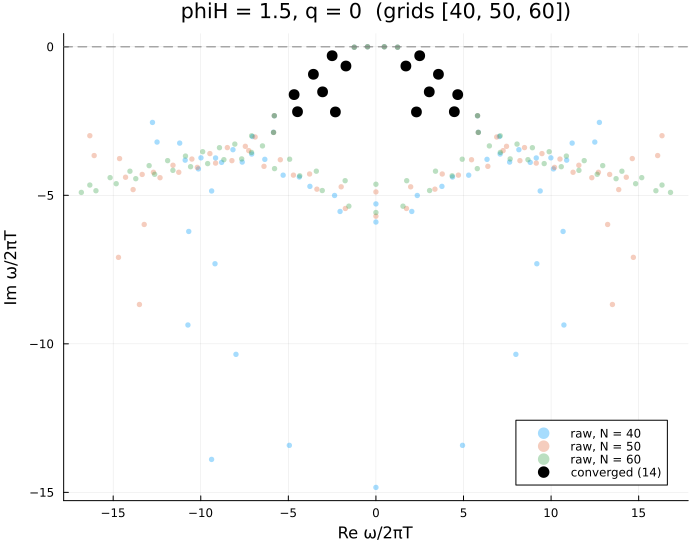

In [14]:
plot_qnms(r)

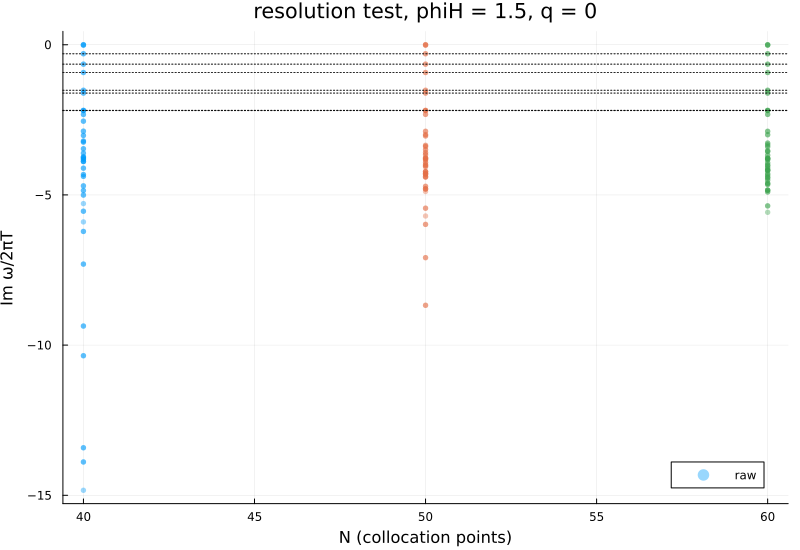

In [15]:
plot_convergence(r)

q scan:   2%|██                                         |  ETA: 0:01:24

q scan:   4%|██                                         |  ETA: 0:01:14

q scan:   5%|███                                        |  ETA: 0:01:09

q scan:   6%|███                                        |  ETA: 0:01:07

q scan:   8%|████                                       |  ETA: 0:01:04

q scan:   9%|████                                       |  ETA: 0:01:02

q scan:  10%|█████                                      |  ETA: 0:01:00

q scan:  11%|█████                                      |  ETA: 0:00:59

q scan:  12%|██████                                     |  ETA: 0:00:57

q scan:  14%|██████                                     |  ETA: 0:00:56

q scan:  15%|███████                                    |  ETA: 0:00:54

q scan:  16%|███████                                    |  ETA: 0:00:53

q scan:  18%|████████                                   |  ETA: 0:00:52

q scan:  19%|█████████                             

phiH = 1.1600   T/Lambda = 0.37403   3840 raw / 328 converged over 80 momenta
seeded 2 track(s) at q = 0.005
  track 1: 80 pts, Im +0.00127 -> -0.00412, unstable for q <= 0.380, leaves the axis never
  track 2: 80 pts, Im -0.00131 -> -0.23547, unstable for q <= never, leaves the axis never


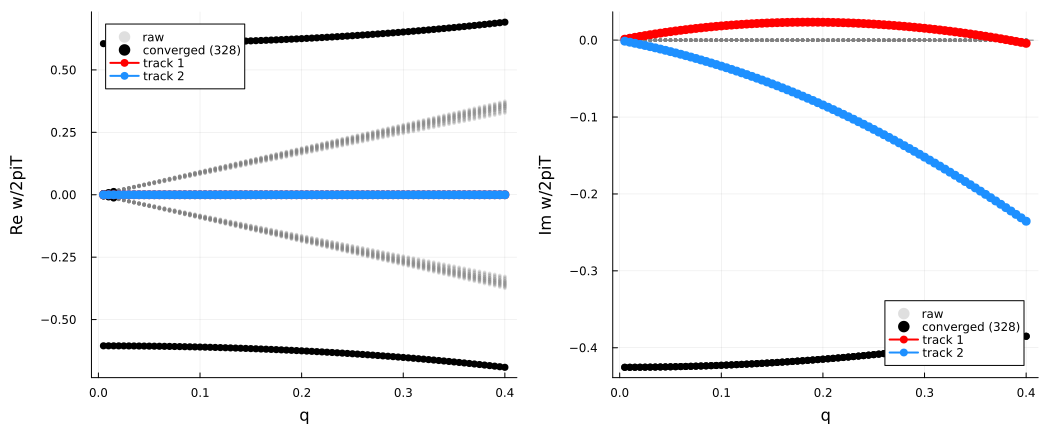

In [16]:
# All modes as a function of q on the spinodal branch.  Faint grey is the raw spectrum
# of each grid, black the modes that converge across all of them, and the purely
# imaginary modes are followed in q and drawn in colour.  `bcexpand = true` resolves the
# light modes.
phiH_scan = 1.16
qs_scan   = 0.005:0.005:0.4
bscan     = background(m, phiH_scan; N = 60)

qraw = Float64[]; lraw = ComplexF64[]
byq  = Vector{Vector{ComplexF64}}()
bar  = Progress(length(qs_scan); desc = "q scan: ")
for q in qs_scan
    r = qnms(m, phiH_scan; q = q, Ns = (40, 50, 60), rtol = 1e-4, cutoff = 2.0,
             bcexpand = true, verbose = false, progress = false)
    sc = 2pi * r.T
    for w in r.raw                                  # pooled over the three grids
        append!(qraw, fill(q, length(w))); append!(lraw, w ./ sc)
    end
    good = [r.lambda[i] for i in eachindex(r.lambda) if r.err[i] < 1e-2 * abs(r.lambda[i])]
    push!(byq, sort(good, by = z -> -imag(z)))
    QUASTELL._tick!(bar, [(:q, q), (:converged, length(good))])
end
qcon = vcat([fill(q, length(byq[i])) for (i, q) in enumerate(qs_scan)]...)
lcon = vcat(byq...)
@printf("phiH = %.4f   T/Lambda = %.5f   %d raw / %d converged over %d momenta\n",
        phiH_scan, bscan.T/bscan.Lambda, length(lraw), length(lcon), length(qs_scan))

# --- follow the purely imaginary modes ---------------------------------------
axtol  = 1e-4      # |Re lambda| below this counts as "on the axis"
ntrack = 4         # how many to follow from the seed, least damped first
gate   = 0.05      # abandon a branch if the nearest mode is further than this
qv     = collect(qs_scan)
i0     = findfirst(i -> any(z -> abs(real(z)) < axtol, byq[i]), eachindex(byq))
tracks = Vector{Vector{ComplexF64}}(); tq = Vector{Vector{Float64}}()
if i0 === nothing
    println("no mode on the imaginary axis at any q -- nothing to track")
else
    seed = filter(z -> abs(real(z)) < axtol, byq[i0])
    seed = seed[1:min(ntrack, length(seed))]
    tracks = [ComplexF64[z] for z in seed]
    tq     = [Float64[qv[i0]] for _ in seed]
    for i in (i0+1):length(qv)
        cand = copy(byq[i])
        for (b, tr) in enumerate(tracks)
            isempty(cand) && continue
            prev = tr[end]
            pred = length(tr) >= 2 ? prev + (prev - tr[end-1]) : prev   # linear in q
            k = argmin(abs.(cand .- pred))
            abs(cand[k] - pred) > gate && continue                      # branch lost
            push!(tr, cand[k]); push!(tq[b], qv[i]); deleteat!(cand, k)
        end
    end
    @printf("seeded %d track(s) at q = %.3f\n", length(tracks), qv[i0])
    for (b, tr) in enumerate(tracks)
        off = findfirst(z -> abs(real(z)) > axtol, tr)
        up  = findall(z -> imag(z) > 1e-8, tr)
        @printf("  track %d: %2d pts, Im %+.5f -> %+.5f, unstable for q <= %s, leaves the axis %s\n",
                b, length(tr), imag(tr[1]), imag(tr[end]),
                isempty(up) ? "never" : @sprintf("%.3f", tq[b][up[end]]),
                off === nothing ? "never" : @sprintf("at q = %.3f", tq[b][off]))
    end
end

p_re = scatter(qraw, real.(lraw); ms = 2, msw = 0, alpha = 0.25, c = :gray,
               label = "raw", xlabel = "q", ylabel = "Re w/2piT")
scatter!(p_re, qcon, real.(lcon); ms = 4, msw = 0, c = :black,
         label = "converged ($(length(lcon)))")
p_im = scatter(qraw, imag.(lraw); ms = 2, msw = 0, alpha = 0.25, c = :gray,
               label = "raw", xlabel = "q", ylabel = "Im w/2piT")
scatter!(p_im, qcon, imag.(lcon); ms = 4, msw = 0, c = :black,
         label = "converged ($(length(lcon)))")
hline!(p_im, [0.0]; ls = :dash, c = :gray, label = "")

cols = [:red, :dodgerblue, :seagreen, :orange]
for (b, tr) in enumerate(tracks)
    c = cols[mod1(b, length(cols))]
    plot!(p_re, tq[b], real.(tr); c = c, lw = 2, m = :circle, ms = 5, msw = 0,
          label = "track $b")
    plot!(p_im, tq[b], imag.(tr); c = c, lw = 2, m = :circle, ms = 5, msw = 0,
          label = "track $b")
end
plot(p_re, p_im; layout = (1, 2), size = (1050, 430), legend = :best,
     left_margin = 6Plots.mm, bottom_margin = 5Plots.mm)

### 6. Validation: AdS brane limit
At `phiH -> 0` the channels decouple and each must reproduce its AdS5-Schwarzschild tower: Z2 the `Delta = 4` one, Zphi the `Delta = 3` one (the bulk scalar has `m^2 = V''(0) = -3`). The sound mode must go to `+-q/sqrt(3) - i q^2/3`.

In [17]:
tree = [1.559725796-1.373337872im, 2.584760-2.381785im, 3.594-3.385im]  # Delta = 4
scal = [1.099407283-0.879767314im, 2.105948627-1.887444155im,
        3.107718-2.888602im]                              # Delta = 3
q = 0.05*0
rv = qnms(m, 1e-3; q = q, Ns = (40, 50, 60), rtol = 1e-4, cutoff = 40.0, verbose = false,
            progress = true)
pos = sort(filter(z -> real(z) > 1e-6, rv.lambda), by = z -> -imag(z))
e1 = q/sqrt(3) - im*q^2/3
@printf("%-28s %-28s %-9s %s\n", "computed", "expected", "|diff|", "")
for z in pos
    j = findfirst(t -> abs(z-t) < 0.03, tree)
    k = findfirst(t -> abs(z-t) < 0.03, scal)
    ref = j !== nothing ? tree[j] : k !== nothing ? scal[k] :
          abs(z-e1) < 0.01 ? e1 : NaN+NaN*im
    lbl = j !== nothing ? "Z2   n=$j" : k !== nothing ? "Zphi n=$k" :
          abs(z-e1) < 0.01 ? "sound" : "?"
    @printf("%+.9f%+.9fi   %+.9f%+.9fi   %-9.1e %s\n",
            real(z), imag(z), real(ref), imag(ref), abs(z-ref), lbl)
end

qnms:  67%|███████████████████████████████              |  ETA: 0:00:00

qnms: 100%|█████████████████████████████████████████████| Time: 0:00:00
             N: 60
   eigenvalues: 204


computed                     expected                     |diff|    
+1.099407486-0.879767046i   +1.099407283-0.879767314i   3.4e-07   Zphi n=1
+1.559725860-1.373337493i   +1.559725796-1.373337872i   3.8e-07   Z2   n=1
+2.105948706-1.887443632i   +2.105948627-1.887444155i   5.3e-07   Zphi n=2
+2.584760532-2.381784577i   +2.584760000-2.381785000i   6.8e-07   Z2   n=2
+3.107767306-2.888628232i   +3.107718000-2.888602000i   5.6e-05   Zphi n=3
+3.594002214-3.384726817i   +3.594000000-3.385000000i   2.7e-04   Z2   n=3


┌ Warning: q = 0: discarding the degenerate band at omega = 0 (|omega/2piT| < 0.001).  The gapped tower is unaffected, but the hydrodynamic mode also sits exactly at omega = 0 here and cannot be separated from it -- use a small nonzero q for that.
└ @ QUASTELL c:\Users\pedro\Desktop\ESTUDIOS\PhD in Theoretical Physics\3 year\Instabilities_project\QNMs codes\QUASTELL\src\qnms.jl:141


The Christmas tree: two towers plus the hydrodynamic mode at the origin.

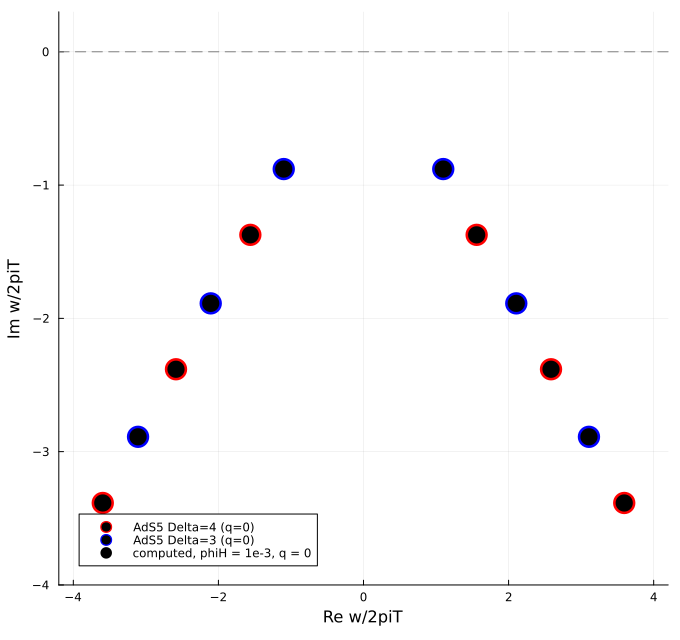

In [18]:
pt = scatter(vcat(real.(tree), -real.(tree)), vcat(imag.(tree), imag.(tree)),
             ms = 11, mc = :transparent, msc = :red, msw = 2,
             label = "AdS5 Delta=4 (q=0)", legend = :bottomleft,
             xlabel = "Re w/2piT", ylabel = "Im w/2piT",
             size = (680, 640), xlims = (-4.2, 4.2), ylims = (-4, 0.3))
scatter!(pt, vcat(real.(scal), -real.(scal)), vcat(imag.(scal), imag.(scal)),
         ms = 11, mc = :transparent, msc = :blue, msw = 2,
         label = "AdS5 Delta=3 (q=0)")
hline!(pt, [0.0], ls = :dash, c = :gray, label = "")
scatter!(pt, real.(rv.lambda), imag.(rv.lambda), ms = 6, c = :black, msw = 0,
         label = "computed, phiH = 1e-3, q = 0")

### 7. Dispersion relation
Branches are tracked in q by continuation after folding the `+-Re` symmetry, so `dRe(lambda)/dq` at small q *is* the speed of sound; `sound_speed` fits `Re lambda = cs q + b q^3`.

dispersion:   1%|█                                      |  ETA: 0:09:12

dispersion:   2%|█                                      |  ETA: 0:07:10

dispersion:   2%|█                                      |  ETA: 0:06:12

dispersion:   3%|██                                     |  ETA: 0:05:22

dispersion:   4%|██                                     |  ETA: 0:04:49

dispersion:   4%|██                                     |  ETA: 0:04:29

dispersion:   5%|██                                     |  ETA: 0:04:14

dispersion:   6%|███                                    |  ETA: 0:04:03

dispersion:   6%|███                                    |  ETA: 0:03:55

dispersion:   7%|███                                    |  ETA: 0:03:47

dispersion:   8%|███                                    |  ETA: 0:03:40

dispersion:   8%|████                                   |  ETA: 0:03:32

dispersion:   9%|████                                   |  ETA: 0:03:28

dispersion:   9%|████                              

cs = 0.577349851   cs^2 = 0.333332850   (conformal: 0.577350269, 1/3)   residual 0.0e+00


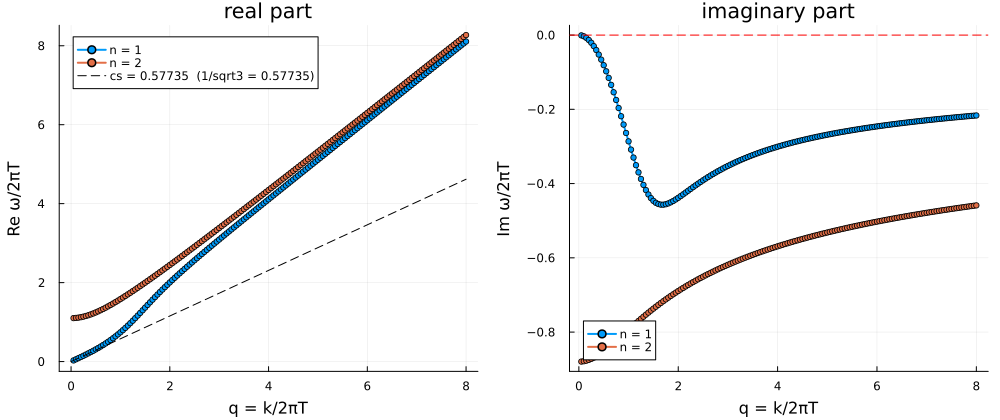

In [19]:
d = dispersion(m, 1e-4; qs = 0.05:0.05:8.0, nmodes = 2, Ns = (40, 50, 60),
               rtol = 1e-4, cutoff = 40.0);
cs, res = sound_speed(d; nmax = 2)
@printf("cs = %.9f   cs^2 = %.9f   (conformal: %.9f, 1/3)   residual %.1e\n",
        cs, cs^2, 1/sqrt(3), res)
plot_dispersion(d)

### 8. Instability on the spinodal branch
Where `ds/dT < 0` (here `phiH` between 1.033 and 1.271) the sound mode turns purely imaginary and one root crosses to `Im > 0`. It shows at small nonzero `q`: at `q = 0` the sound mode sits at the origin, which `qnms` drops. Light modes need `bcexpand = true`. Nothing is filtered on stability; `plot_qnms` marks unstable modes with a red star.

In [20]:
r2 = qnms(m, 1.16; q = 0.05, Ns = (40, 50, 60), rtol = 1e-4, cutoff = 40.0, bcexpand = true)
keep = [i for i in eachindex(r2.lambda) if r2.err[i] < 1e-2 * abs(r2.lambda[i])]
@printf("%4s  %-22s %-22s %s\n", "n", "Re(w/2piT)", "Im(w/2piT)", "err")
for (n, i) in enumerate(keep[1:min(6, end)])
    @printf("%4d  %-22.12g %-22.12g %.2e\n", n, real(r2.lambda[i]), imag(r2.lambda[i]), r2.err[i])
end

  N =  40 :  225 finite eigenvalues
  N =  50 :  276 finite eigenvalues
  N =  60 :  312 finite eigenvalues
  dropped 534 eigenvalues at omega^2 = a(u_i), band |lambda|/q in [0.7496, 1.0000]
  converged on all 3 grids: 16 modes  (T = 0.355732)
  *** 1 mode(s) with Im(omega) > 0: UNSTABLE ***
   n  Re(w/2piT)             Im(w/2piT)             err
   1  6.8371248286e-12       0.011067887208         1.24e-09
   2  -7.45525143091e-12     -0.0148734264496       1.84e-09
   3  0.606471971149         -0.424804075748        4.25e-09
   4  -0.606471971149        -0.424804075748        4.25e-09
   5  -1.46282111307         -0.835518047383        4.92e-09
   6  1.46282111307          -0.835518047383        4.92e-09


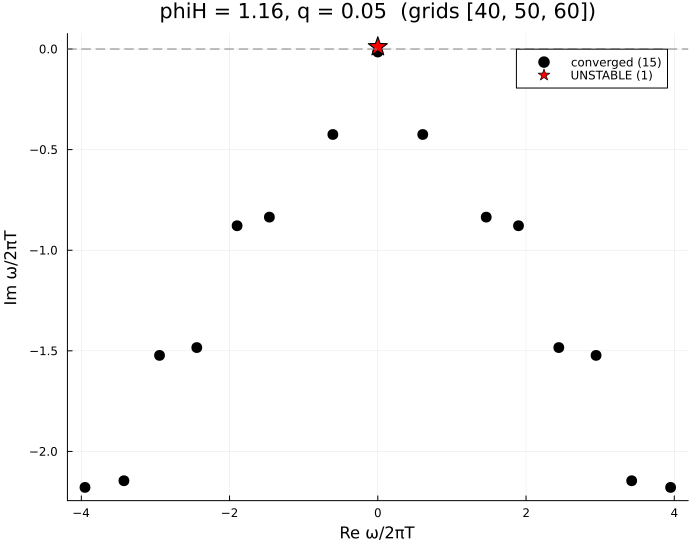

In [21]:
plot_qnms(r2; showraw = false)

### 9. Growth rate, checked against the equation of state
In the spinodal region `cs^2 < 0`, so `gamma = Im omega = |cs| k - Gamma k^2/2`: an inverted parabola vanishing at `k = 2|cs|/Gamma`. Its slope at the origin must agree with `cs^2 = dp/de = (s/T)/(ds/dT)` taken straight from the thermodynamics, which never enters the QNM computation.

In [22]:
phiH = 1.16
ok = findall(th.converged); i = ok[argmin(abs.(th.phiH[ok] .- phiH))]
for h in (2, 5)
    dsdT = (th.s[i+h] - th.s[i-h]) / (th.t[i+h] - th.t[i-h])
    cs2  = (th.s[i]/th.t[i]) / dsdT
    @printf("thermodynamics, stencil +-%d : ds/dT = %+.5f  cs^2 = %+.5f  |cs| = %.5f\n",
            h, dsdT, cs2, sqrt(abs(cs2)))
end
g = growth_rate(m, phiH; qs = 0.005:0.005:0.03, Ns = (40, 50, 60), rtol = 1e-4,
                bcexpand = true, cutoff = 40.0, nfit = 3, progress = false)
@printf("QNM growth rate            : |cs| = %.5f\n", g.cs)

thermodynamics, stencil +-2 : ds/dT = -70.81359  cs^2 = -0.06687  |cs| = 0.25859
thermodynamics, stencil +-5 : ds/dT = -70.97247  cs^2 = -0.06672  |cs| = 0.25830
QNM growth rate            : |cs| = 0.25871


In [23]:
g2 = growth_rate(m, 1.16; qs = 0.01:0.02:0.41, Ns = (40, 50, 60), rtol = 1e-4,
                 bcexpand = true, cutoff = 40.0)
@printf("T/Lambda = %.5f   |cs| = %.5f   Gamma = %.5f   k_max/Lambda = %.4f\n",
        g2.TL, g2.cs, g2.Gamma, g2.kmax)
@printf("%9s %14s %14s\n", "k/Lambda", "gamma/Lambda", "hydro (2.16)")
for i in eachindex(g2.kL)
    @printf("%9.4f %14.7f %14.7f\n", g2.kL[i], g2.gL[i],
            g2.cs*g2.kL[i] - 0.5*g2.Gamma*g2.kL[i]^2)
end

dispersion:  10%|████                                   |  ETA: 0:00:24

dispersion:  14%|██████                                 |  ETA: 0:00:22

dispersion:  19%|████████                               |  ETA: 0:00:20

dispersion:  24%|██████████                             |  ETA: 0:00:18

dispersion:  29%|████████████                           |  ETA: 0:00:17

dispersion:  33%|██████████████                         |  ETA: 0:00:16

dispersion:  38%|███████████████                        |  ETA: 0:00:15

dispersion:  43%|█████████████████                      |  ETA: 0:00:14

dispersion:  48%|███████████████████                    |  ETA: 0:00:13

dispersion:  52%|█████████████████████                  |  ETA: 0:00:12

dispersion:  57%|███████████████████████                |  ETA: 0:00:10

dispersion:  62%|█████████████████████████              |  ETA: 0:00:09

dispersion:  67%|███████████████████████████            |  ETA: 0:00:08

dispersion:  71%|████████████████████████████      

T/Lambda = 0.37403   |cs| = 0.25843   Gamma = 0.63117   k_max/Lambda = 0.8189
 k/Lambda   gamma/Lambda   hydro (2.16)
   0.0235      0.0059024      0.0058991
   0.0705      0.0166494      0.0166516
   0.1175      0.0260104      0.0260097
   0.1645      0.0340143      0.0339735
   0.2115      0.0406890      0.0405430
   0.2585      0.0460609      0.0457181
   0.3055      0.0501553      0.0494989
   0.3525      0.0529963      0.0518854
   0.3995      0.0546064      0.0528775
   0.4465      0.0550066      0.0524753
   0.4935      0.0542169      0.0506787
   0.5405      0.0522554      0.0474878
   0.5875      0.0491391      0.0429026
   0.6345      0.0448837      0.0369231
   0.6815      0.0395034      0.0295492
   0.7285      0.0330109      0.0207809
   0.7755      0.0254180      0.0106184
   0.8225      0.0167350     -0.0009385
   0.8695      0.0069709     -0.0138898
   0.9165     -0.0038664     -0.0282353
   0.9635     -0.0157704     -0.0439752


phiH = 1.0700:  10%|████                                |  ETA: 0:00:34

phiH = 1.0700:  14%|██████                              |  ETA: 0:00:31

phiH = 1.0700:  19%|███████                             |  ETA: 0:00:27

phiH = 1.0700:  24%|█████████                           |  ETA: 0:00:24

phiH = 1.0700:  29%|███████████                         |  ETA: 0:00:22

phiH = 1.0700:  33%|█████████████                       |  ETA: 0:00:20

phiH = 1.0700:  38%|██████████████                      |  ETA: 0:00:18

phiH = 1.0700:  43%|████████████████                    |  ETA: 0:00:16

phiH = 1.0700:  48%|██████████████████                  |  ETA: 0:00:15

phiH = 1.0700:  52%|███████████████████                 |  ETA: 0:00:13

phiH = 1.0700:  57%|█████████████████████               |  ETA: 0:00:12

phiH = 1.0700:  62%|███████████████████████             |  ETA: 0:00:10

phiH = 1.0700:  67%|█████████████████████████           |  ETA: 0:00:09

phiH = 1.0700:  71%|██████████████████████████     

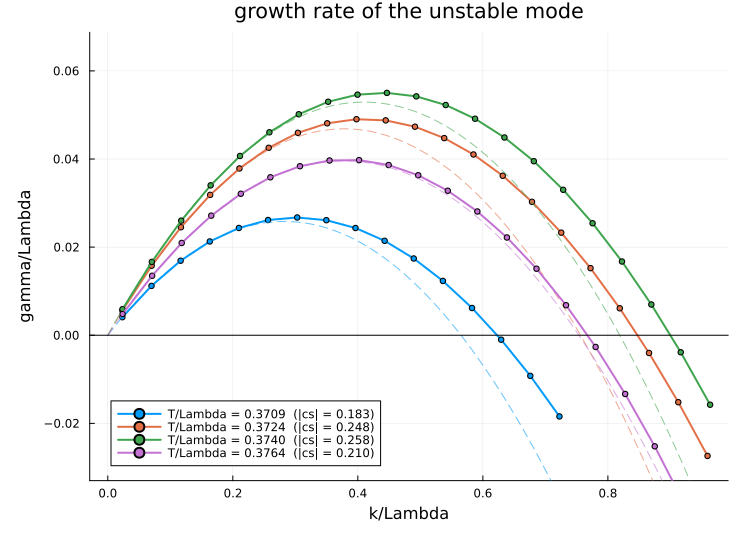

In [24]:
plot_growth_rates(m, (1.07, 1.12, 1.16, 1.22); qs = 0.01:0.02:0.41,
Ns = (40, 50, 60), rtol = 1e-4, bcexpand = true, cutoff = 40.0)

### 10. Cached state
`m` accumulates everything computed so far.

In [25]:
m

Bea_Mateos(phiM = 1.0, phiQ = 10.0, chi = 1.2, nu = 1.0)
  phiMax = 1.539456   V(phiMax) = -7.14223
  cached backgrounds: 24   thermodynamics: 2000 points   Tc: 0.373567
  QNM runs: 362